In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('student_habits_performance.csv')
df

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,S1995,21,Female,2.6,0.5,1.6,No,77.0,7.5,Fair,2,High School,Good,6,Yes,76.1
996,S1996,17,Female,2.9,1.0,2.4,Yes,86.0,6.8,Poor,1,High School,Average,6,Yes,65.9
997,S1997,20,Male,3.0,2.6,1.3,No,61.9,6.5,Good,5,Bachelor,Good,9,Yes,64.4
998,S1998,24,Male,5.4,4.1,1.1,Yes,100.0,7.6,Fair,0,Bachelor,Average,1,No,69.7


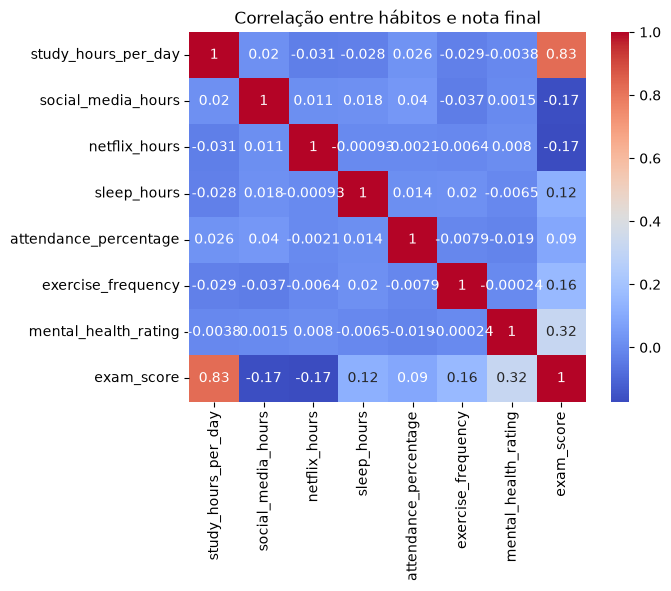

In [4]:
#Colunas numericas
cols = [
    "study_hours_per_day",
    "social_media_hours",
    "netflix_hours",
    "sleep_hours",
    "attendance_percentage",
    "exercise_frequency",
    "mental_health_rating",
    "exam_score",
]

#plotagem mapa de calor(heatmap)
sns.heatmap(df[cols].corr(),annot=True,cmap="coolwarm") #corr() correlação, annot exibe os valores
plt.title("Correlação entre hábitos e nota final")
plt.show()

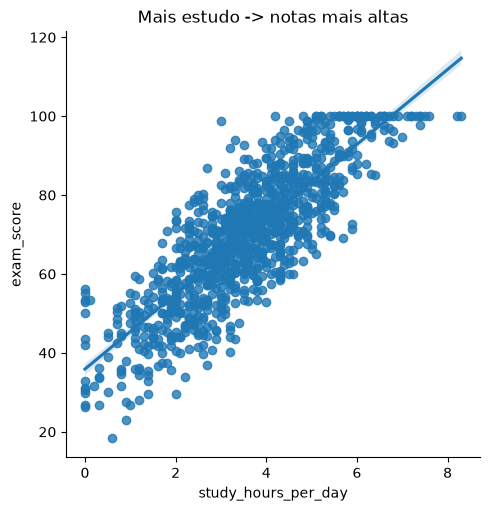

In [5]:
#Gráfico de dispersão com linha de regressão
# x = "study_hours_per_day" / y="exam_score"
sns.lmplot(data=df, x = "study_hours_per_day", y = "exam_score")
plt.title("Mais estudo -> notas mais altas")
plt.show()


In [8]:
#Comparando Médias: quem estuda >5h x <2h

filtro_estudo_alto = df["study_hours_per_day"] > 5
filtro_estudo_baixo = df["study_hours_per_day"] <2

grupo_estudo_alto = df[filtro_estudo_alto]["exam_score"]
grupo_estudo_baixo = df[filtro_estudo_baixo]["exam_score"]

print("Média notas (estuda>5):", grupo_estudo_alto.mean())
print("Média notas (estuda<2):", grupo_estudo_baixo.mean())

Média notas (estuda>5): 90.79419354838709
Média notas (estuda<2): 45.56390977443609


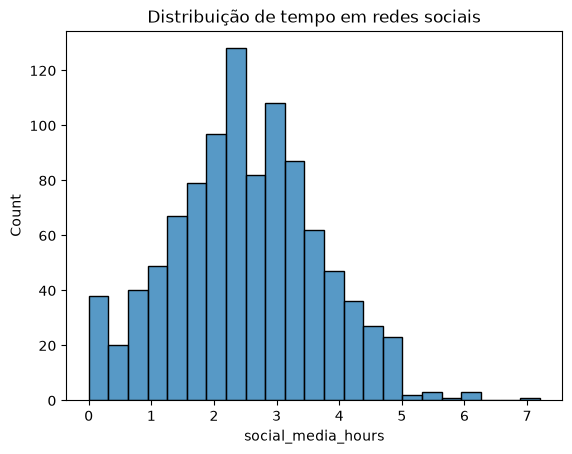

In [9]:
#Redes sociais: distribuição geral (histograma)
# x ="social_media_hours"
sns.histplot(data=df,x ="social_media_hours" )
plt.title("Distribuição de tempo em redes sociais")
plt.show()

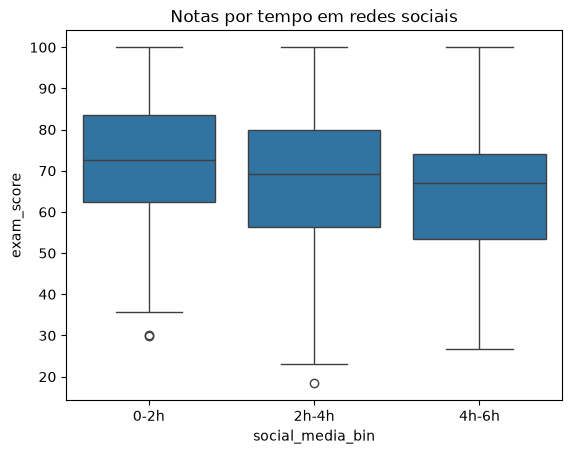

In [14]:
#Avalia notas médias
#por diferentes intervalos (bins) de periodos gastos em redes sociais
#["0-2h","2h-4h","4h-6h","6h+"]
df["social_media_bin"] = pd.cut( df["social_media_hours"],bins =[0,2,4,6],labels=["0-2h","2h-4h","4h-6h",])
sns.boxplot(x = "social_media_bin", y = "exam_score", data=df)
plt.title("Notas por tempo em redes sociais")
plt.show()

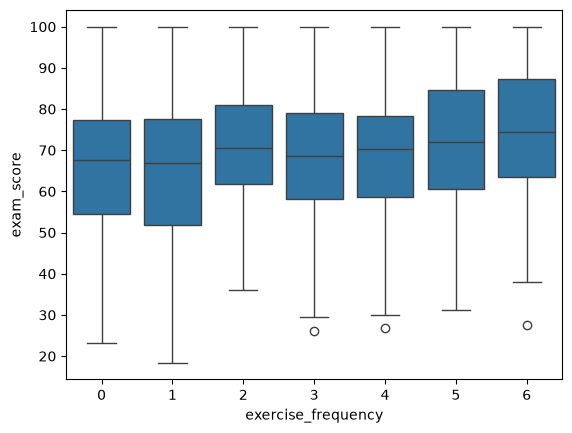

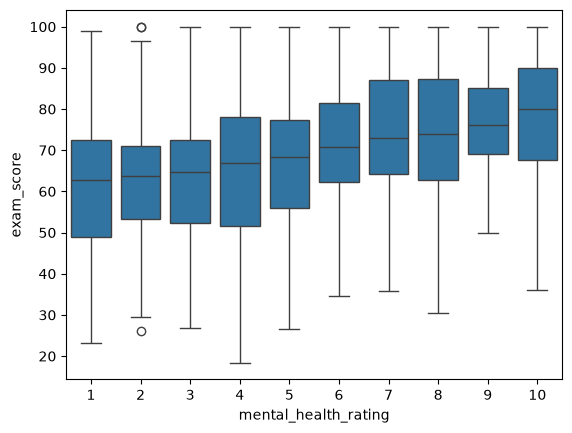

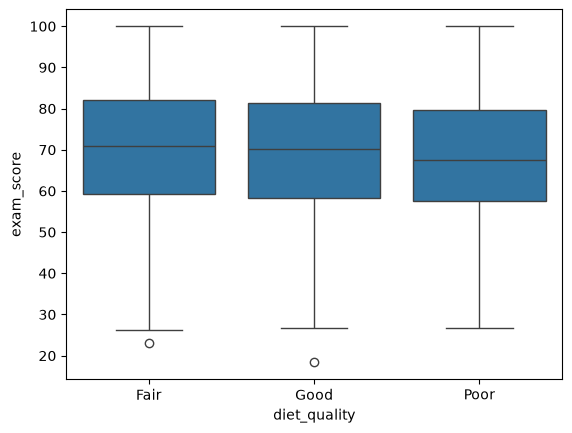

In [15]:
for col in ["exercise_frequency","mental_health_rating","diet_quality"]:
    sns.boxplot(x=col, y= "exam_score", data =df)
    plt.show()

In [16]:
#Estatíscas por gênero(média e desvio padrão)
df.groupby(["gender"])["exam_score"].agg(["mean","std"])

,mean,std
gender,,
Female,69.741372,16.899351
Male,69.368344,17.150875
Other,70.647619,13.755890


In [17]:
#Avalia distribuição de gênero
df["gender"].value_counts(normalize=True)

gender
Female    0.481
Male      0.477
Other     0.042
Name: proportion, dtype: float64